In [1]:
import sys

sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

data = get_runs_data(
    tag="hybrid-frozen-embd",
    project="memorization",
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ],
)
show_config_differences(data)

Found 6 runs with tag 'hybrid-frozen-embd'


,cfg.dataset.total_size,cfg.dataset.token_subset_size
_run_id,,
aq91v364,1000,1000
euz8ihd7,500,1000
ido8gn8v,1000,10
pu6gs9wz,1000,10000
svaqtdb4,500,10000
xguf27mh,500,10


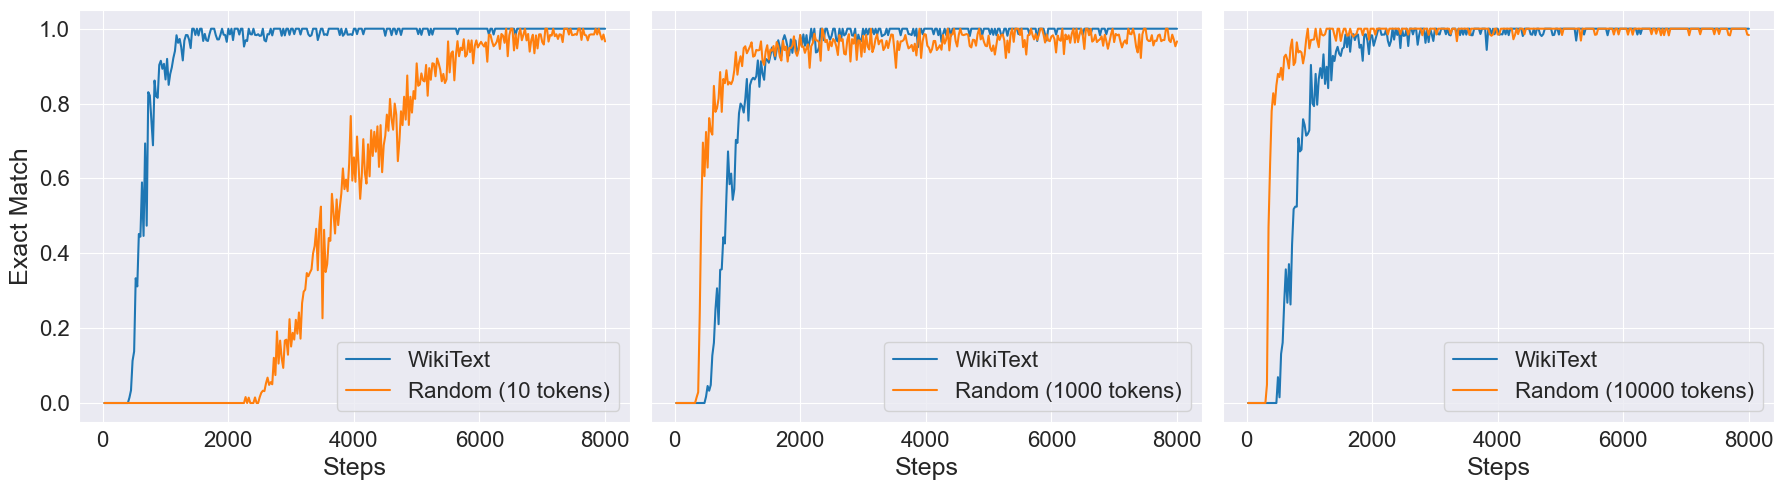

In [8]:
TOTAL_SIZE_COL = "cfg.dataset.total_size"
TOKEN_SUBSET_COL = "cfg.dataset.token_subset_size"
STEP_COL = "train/global_step"
METRICS = ["train/exact_match_wikitext", "train/exact_match_synthetic"]
METRIC_LABELS = {
    "train/exact_match_wikitext": "WikiText",
    "train/exact_match_synthetic": "Random",
}


def plot_runs(total_size):
    filtered = data[data[TOTAL_SIZE_COL] == total_size]
    token_sizes = sorted(filtered[TOKEN_SUBSET_COL].unique())
    n = len(token_sizes)

    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5), sharey=True)
    if n == 1:
        axes = [axes]

    for ax, token_size in zip(axes, token_sizes):
        subset = filtered[filtered[TOKEN_SUBSET_COL] == token_size]

        for metric in METRICS:
            groups = (
                subset.groupby(STEP_COL)[metric]
                .agg(["mean", "std"])
                .reset_index()
            )
            steps = groups[STEP_COL]
            mean = groups["mean"]
            std = groups["std"].fillna(0)

            label = METRIC_LABELS[metric]
            if label == "Random":
                label += f" ({token_size} tokens)"

            ax.plot(steps, mean, label=label)
            ax.fill_between(
                steps, (mean - std).clip(0, 1), (mean + std).clip(0, 1), alpha=0.2
            )

        # ax.set_title(f"Vocab Size Random: {token_size}", fontsize=14)
        ax.set_xlabel("Steps", fontsize=18)
        if ax is axes[0]:
            ax.set_ylabel("Exact Match", fontsize=18)
        ax.legend(fontsize=16)
        ax.tick_params(labelsize=16)

    # fig.suptitle(f"Dataset of 250 WikiText and 250 Random Sequences [Frozen GPT-2 Embeddings]", fontsize=16)
    plt.tight_layout()
    plt.savefig(f"plots/hybrid-frozen-embd.pdf", bbox_inches="tight")
    # plt.show()


plot_runs(total_size=500)